# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:
df = pd.read_csv('data/AviationData_Cleaned.csv', low_memory=False)
print(df.shape)
df.head(10)

(55636, 32)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,Aircraft.Category,Registration.Number,Make,Model,Amateur.Built,Number.of.Engines,Engine.Type,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Fatal.Serious.Rate,Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,Airplane,N1296M,Cessna,182P,No,1.0,Reciprocating,Personal,0.0,0.0,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0,Cessna 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,Non-Fatal,Substantial,Airplane,N2639C,Cessna,182RG,No,1.0,Reciprocating,Personal,0.0,0.0,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,Non-Fatal,Substantial,Airplane,N58664,Cessna,182P,No,1.0,Reciprocating,Personal,0.0,0.0,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0,Cessna 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,Non-Fatal,Substantial,Airplane,N3084R,Piper,PA-28R-200,No,1.0,Reciprocating,Personal,0.0,0.0,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0,Piper PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,Non-Fatal,Substantial,Airplane,N89399,Cessna,140,No,1.0,Reciprocating,Instructional,0.0,0.0,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna 140
5,20001214X42010,Accident,LAX83FA064,1983-01-02,"MONTEREY, CA",United States,NaN,NaN,NaN,NaN,Non-Fatal,Destroyed,Airplane,N1947E,Cessna,340A,No,2.0,Reciprocating,Personal,0.0,0.0,4.0,0.0,VMC,Takeoff,Probable Cause,NaN,4.0,0.0,1,Cessna 340A
6,20001214X41937,Accident,CHI83FA069,1983-01-02,"GENOA CITY, WI",United States,NaN,NaN,64C,VINCENT,Fatal(2),Destroyed,Airplane,N3168G,North American,T-6G,No,1.0,Reciprocating,Personal,2.0,0.0,0.0,0.0,VMC,Maneuvering,Probable Cause,NaN,2.0,1.0,1,North American T-6G
7,20001214X41919,Accident,ATL83FA081,1983-01-02,"BEAUFORT, SC",United States,NaN,NaN,NaN,NaN,Fatal(3),Destroyed,Airplane,N8066P,Piper,PA-24-250,No,1.0,Reciprocating,Personal,3.0,0.0,0.0,0.0,IMC,Cruise,Probable Cause,NaN,3.0,1.0,1,Piper PA-24-250
8,20001214X41976,Accident,DEN83LA047,1983-01-02,"VERNAL, UT",United States,NaN,NaN,VEL,VERNAL MUNI.,Non-Fatal,Substantial,Airplane,N6732B,Beech,A36,No,1.0,Reciprocating,Business,0.0,0.0,0.0,2.0,VMC,Takeoff,Probable Cause,NaN,2.0,0.0,0,Beech A36
9,20001214X41950,Accident,CHI83LA073,1983-01-02,"MONEE, IL",United States,NaN,NaN,C56,SANGER,Non-Fatal,Substantial,Airplane,N9699B,Cessna,180,No,1.0,Reciprocating,Personal,0.0,0.0,0.0,4.0,VMC,Landing,Probable Cause,NaN,4.0,0.0,0,Cessna 180


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [4]:
# client wants separate results for small and large planes: split at 20 people on board
small = df[df['Total.Passengers'] <= 20].copy()
large = df[df['Total.Passengers'] > 20].copy()
print('Small planes:', len(small))
print('Large planes:', len(large))

Small planes: 54687
Large planes: 949


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

                                 mean  count
Make                                        
Grumman-Schweizer               0.103    118
Bombardier                      0.124     26
Waco                            0.131     98
Mcdonnell Douglas               0.134     48
Great Lakes                     0.142     53
Maule                           0.163    496
Helio                           0.166     69
Boeing                          0.167    465
Schweizer                       0.171    140
Swearingen                      0.178     85
Grumman                         0.179    965
Aviat                           0.200    222
Wsk Pzl Mielec                  0.202     57
Stinson                         0.204    392
Grumman Acft Eng Cor-Schweizer  0.207     58 

                    mean  count
Make                           
Mcdonnell Douglas  0.023    166
Bombardier         0.040     61
Embraer            0.091     52
Boeing             0.108    537
Douglas            0.115     31
Airbus   

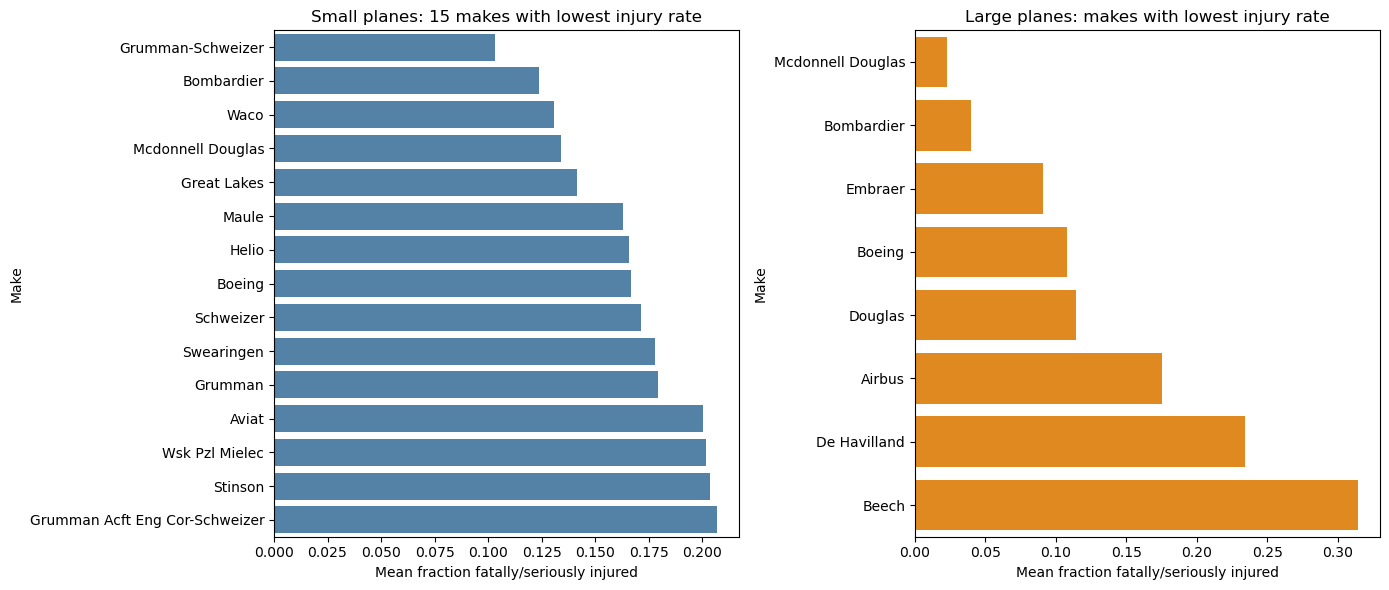

In [5]:
# average injury rate per make, keeping only makes with at least 10 accidents 
def lowest_makes(data, n=15, min_count=10):
    stats = data.groupby('Make')['Fatal.Serious.Rate'].agg(['mean', 'count'])
    return stats[stats['count'] >= min_count].sort_values('mean').head(n)

small_makes = lowest_makes(small)
large_makes = lowest_makes(large)
print(small_makes.round(3), '\n')
print(large_makes.round(3))


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_makes['mean'], y=small_makes.index, ax=axes[0], color='steelblue')
axes[0].set_title('Small planes: 15 makes with lowest injury rate')
axes[0].set_xlabel('Mean fraction fatally/seriously injured')
sns.barplot(x=large_makes['mean'], y=large_makes.index, ax=axes[1], color='darkorange')
axes[1].set_title('Large planes: makes with lowest injury rate')
axes[1].set_xlabel('Mean fraction fatally/seriously injured')
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

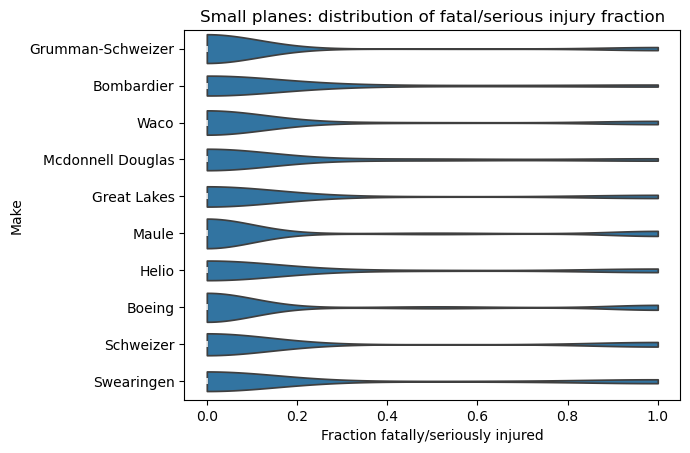

In [6]:
# distribution of injury rates for the 10 small makes with the lowest mean
top10_small = small_makes.head(10).index
sns.violinplot(data=small[small['Make'].isin(top10_small)],
               x='Fatal.Serious.Rate', y='Make', order=top10_small, cut=0)
plt.title('Small planes: distribution of fatal/serious injury fraction')
plt.xlabel('Fraction fatally/seriously injured')
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

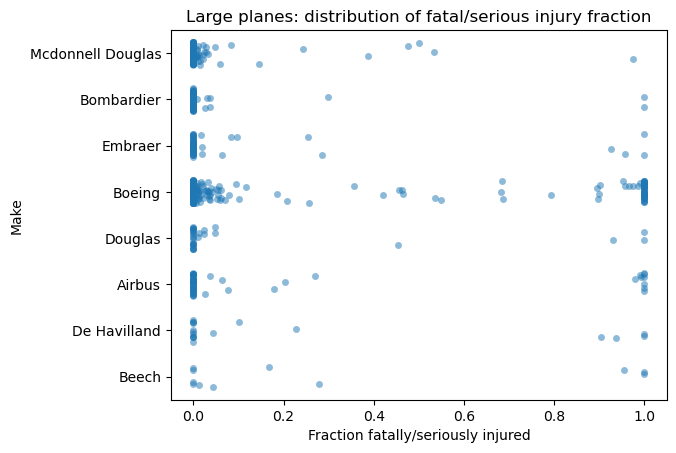

In [7]:
# distribution of injury rates for large makes 
top10_large = large_makes.head(10).index
sns.stripplot(data=large[large['Make'].isin(top10_large)],
              x='Fatal.Serious.Rate', y='Make', order=top10_large, alpha=0.5, jitter=0.25)
plt.title('Large planes: distribution of fatal/serious injury fraction')
plt.xlabel('Fraction fatally/seriously injured')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

                                 mean  count
Make                                        
Grumman Acft Eng Cor-Schweizer  0.017     58
Dehavilland                     0.043     94
Diamond Aircraft Ind            0.054     74
Diamond                         0.059     51
Flight Design Gmbh              0.060     50
Aviat                           0.063    222
Maule                           0.093    496
Ercoupe                         0.097     72
Luscombe                        0.102    364
Waco                            0.102     98
American Champion               0.103     68
Taylorcraft                     0.109    329
Great Lakes                     0.113     53
Bombardier                      0.115     26
Rockwell International          0.119     67 

                    mean  count
Make                           
Bombardier         0.033     61
Mcdonnell Douglas  0.060    166
Embraer            0.077     52
Boeing             0.117    537
Airbus             0.161     56
Douglas  

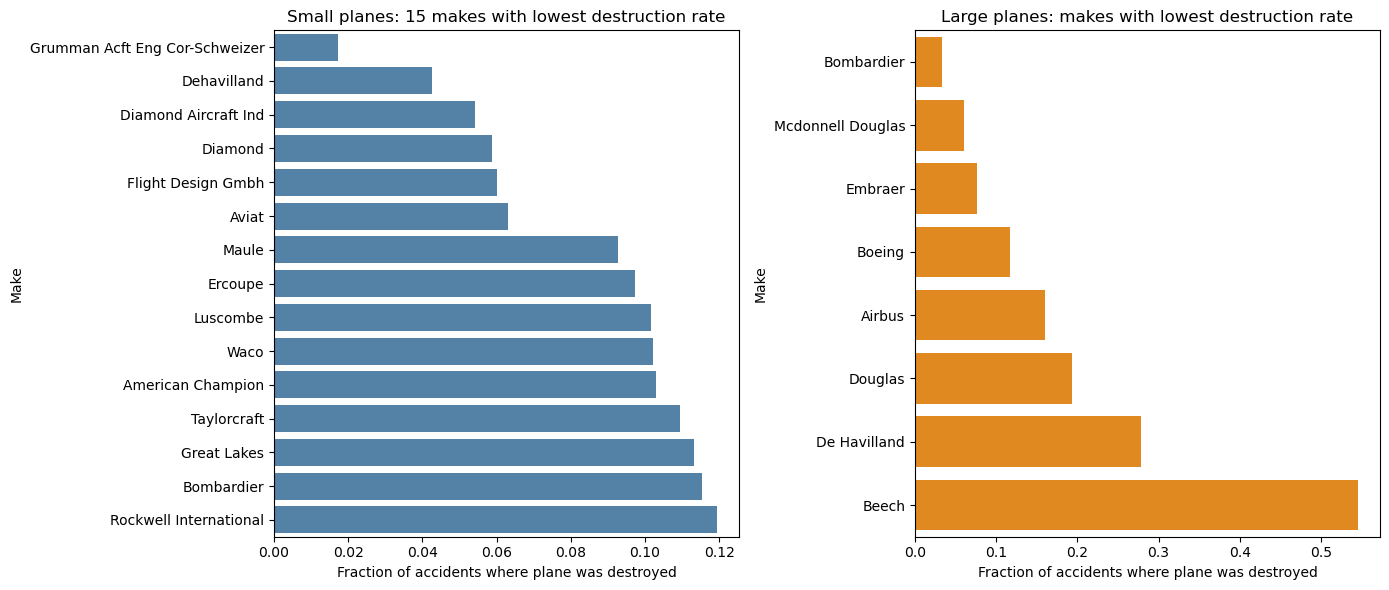

In [8]:

def lowest_destroyed(data, n=15, min_count=10):
    stats = data.groupby('Make')['Destroyed'].agg(['mean', 'count'])
    return stats[stats['count'] >= min_count].sort_values('mean').head(n)

small_destroyed = lowest_destroyed(small)
large_destroyed = lowest_destroyed(large)
print(small_destroyed.round(3), '\n')
print(large_destroyed.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_destroyed['mean'], y=small_destroyed.index, ax=axes[0], color='steelblue')
axes[0].set_title('Small planes: 15 makes with lowest destruction rate')
axes[0].set_xlabel('Fraction of accidents where plane was destroyed')
sns.barplot(x=large_destroyed['mean'], y=large_destroyed.index, ax=axes[1], color='darkorange')
axes[1].set_title('Large planes: makes with lowest destruction rate')
axes[1].set_xlabel('Fraction of accidents where plane was destroyed')
plt.tight_layout()
plt.show()

                                 mean  count
Make                                        
Grumman Acft Eng Cor-Schweizer  0.017     58
Dehavilland                     0.043     94
Diamond Aircraft Ind            0.054     74
Diamond                         0.059     51
Flight Design Gmbh              0.060     50
Aviat                           0.063    222
Maule                           0.093    496
Ercoupe                         0.097     72
Luscombe                        0.102    364
Waco                            0.102     98
American Champion               0.103     68
Taylorcraft                     0.109    329
Great Lakes                     0.113     53
Bombardier                      0.115     26
Rockwell International          0.119     67 

                    mean  count
Make                           
Bombardier         0.033     61
Mcdonnell Douglas  0.060    166
Embraer            0.077     52
Boeing             0.117    537
Airbus             0.161     56
Douglas  

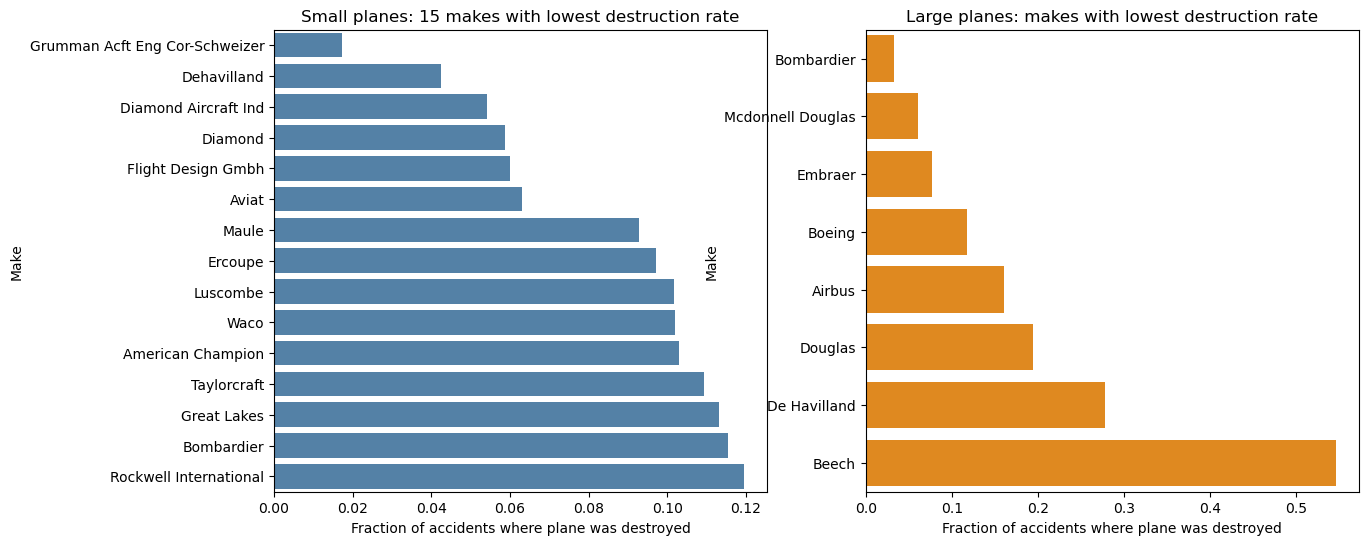

In [9]:

def lowest_destroyed(data, n=15, min_count=10):
    stats = data.groupby('Make')['Destroyed'].agg(['mean', 'count'])
    return stats[stats['count'] >= min_count].sort_values('mean').head(n)

small_destroyed = lowest_destroyed(small)
large_destroyed = lowest_destroyed(large)
print(small_destroyed.round(3), '\n')
print(large_destroyed.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_destroyed['mean'], y=small_destroyed.index, ax=axes[0], color='steelblue')
axes[0].set_title('Small planes: 15 makes with lowest destruction rate')
axes[0].set_xlabel('Fraction of accidents where plane was destroyed')
sns.barplot(x=large_destroyed['mean'], y=large_destroyed.index, ax=axes[1], color='darkorange')
axes[1].set_title('Large planes: makes with lowest destruction rate')
axes[1].set_xlabel('Fraction of accidents where plane was destroyed')
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

**Summary**
- Only makes with at least 10 accidents were considered for comparison. Makes with lesser than 10 accidents were considered to have unreliable data.

- For large planes (more than 20 people on board), McDonnell Douglas, Bombardier and Embraer come out best on both measures. In McDonnell Douglas accidents, about 2% of people on board were killed or seriously injured and the plane was destroyed in 6% of cases. Bombardier and Embraer are similar. Boeing is slightly higher, around 11% on both measures but it has the most accidents in the data. Only 8 large plane makes had enough accidents to compare. This group is small.

- For small planes, the makes that do well on both injuries and destruction are Maule and Aviat. Both have hundreds of accidents in the data so their results are reliable.

- I recommend McDonnell Douglas, Bombardier, Embraer and Boeing for large planes, and Maule and Aviat for small planes.


### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

                             mean  count
Make.Model                              
Boeing 777                  0.000     16
Boeing 757-222              0.000     10
Boeing 757-232              0.000     10
Mcdonnell Douglas MD-83     0.001     13
Mcdonnell Douglas MD-80     0.001     11
Mcdonnell Douglas MD-88     0.003     20
Mcdonnell Douglas DC-9-51   0.006     11
Bombardier CL-600-2B19      0.006     21
Mcdonnell Douglas DC-10-30  0.008     12
Boeing 747                  0.010     10
Mcdonnell Douglas MD-11     0.020     15
Mcdonnell Douglas DC-10-10  0.034     16
Boeing 727-200              0.052     20
Mcdonnell Douglas DC-9-82   0.062     16
Boeing 747-400              0.062     11


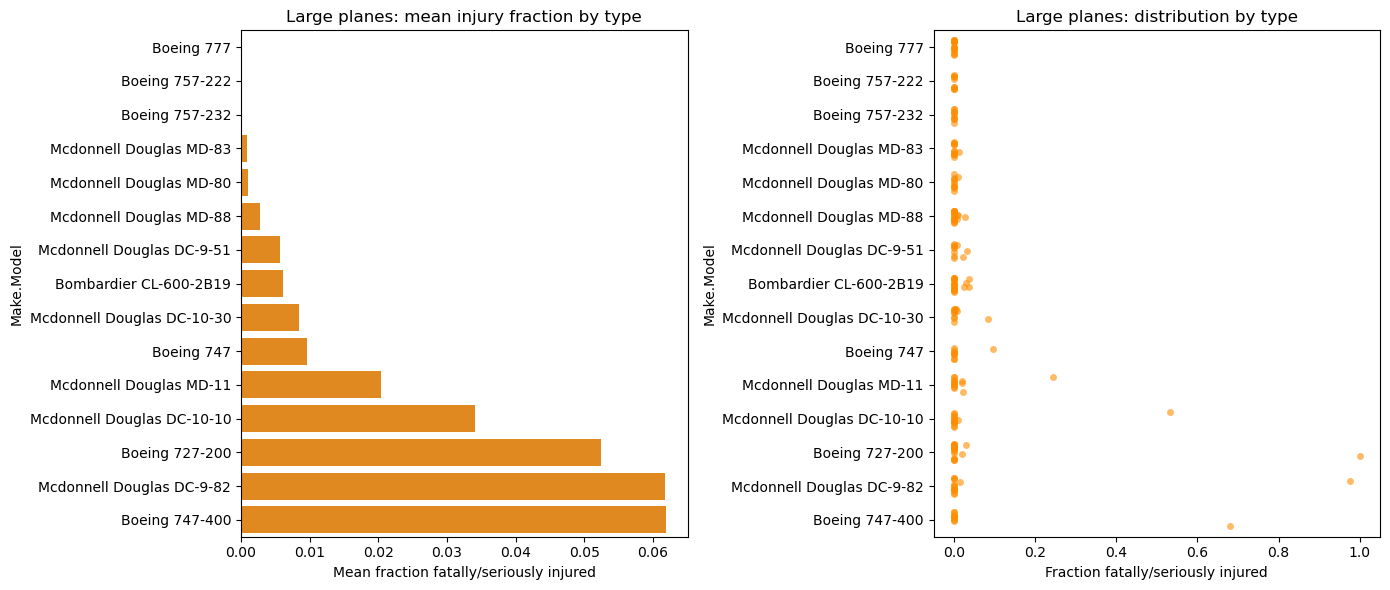

In [10]:
# mean injury rate per plane type. only types with at least 10 accidents
def lowest_types(data, n, min_count=10):
    stats = data.groupby('Make.Model')['Fatal.Serious.Rate'].agg(['mean', 'count'])
    return stats[stats['count'] >= min_count].sort_values('mean').head(n)

large_types = lowest_types(large, 15)
print(large_types.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=large_types['mean'], y=large_types.index, ax=axes[0], color='darkorange')
axes[0].set_title('Large planes: mean injury fraction by type')
axes[0].set_xlabel('Mean fraction fatally/seriously injured')
sns.stripplot(data=large[large['Make.Model'].isin(large_types.index)],
              x='Fatal.Serious.Rate', y='Make.Model', order=large_types.index,
              ax=axes[1], alpha=0.6, jitter=0.25, color='darkorange')
axes[1].set_title('Large planes: distribution by type')
axes[1].set_xlabel('Fraction fatally/seriously injured')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

                                mean  count
Make.Model                                 
Piper PA-18A 150               0.000     12
Diamond Aircraft Ind DA 20 C1  0.000     11
Cessna 180C                    0.000     15
Grumman G164B                  0.000     16
Maule MX-7-235                 0.029     17
Grumman-Schweizer G-164A       0.034     49
Cessna C172                    0.042     12
North American AT-6G           0.045     11
Piper PA-18-160                0.048     31
Maule M-7-235B                 0.050     10


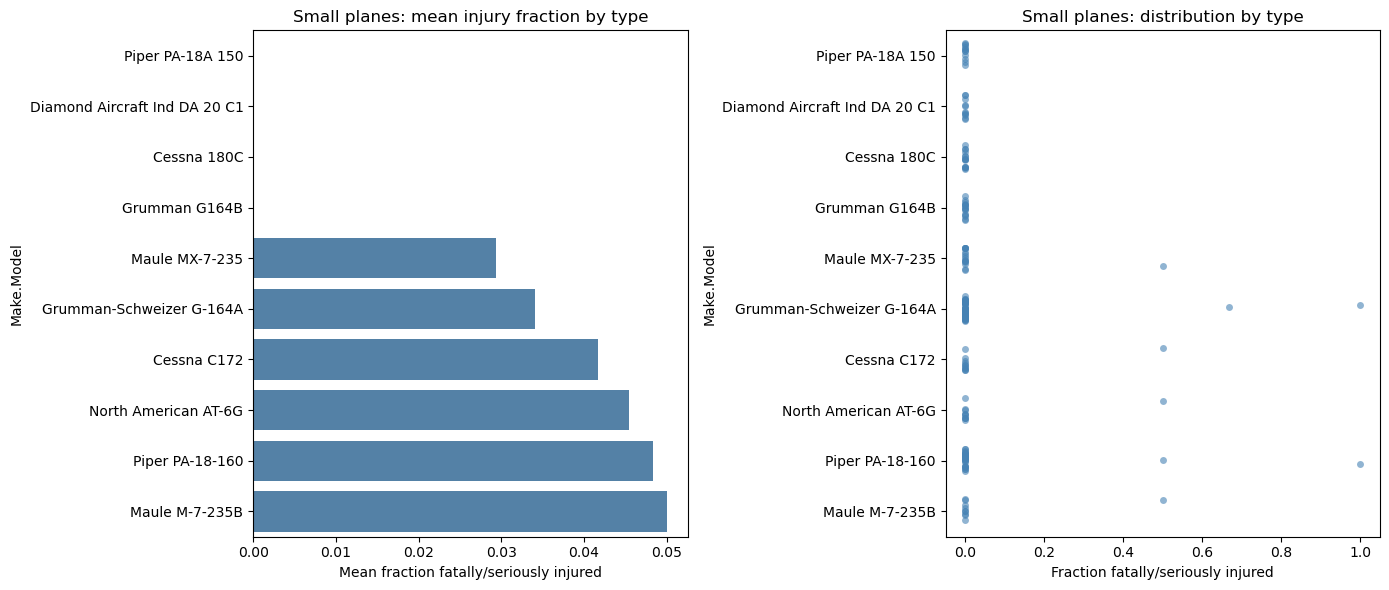

In [11]:
#small planes, limited to the 10 types with the lowest mean
small_types = lowest_types(small, 10)
print(small_types.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_types['mean'], y=small_types.index, ax=axes[0], color='steelblue')
axes[0].set_title('Small planes: mean injury fraction by type')
axes[0].set_xlabel('Mean fraction fatally/seriously injured')
sns.stripplot(data=small[small['Make.Model'].isin(small_types.index)],
              x='Fatal.Serious.Rate', y='Make.Model', order=small_types.index,
              ax=axes[1], alpha=0.6, jitter=0.25, color='steelblue')
axes[1].set_title('Small planes: distribution by type')
axes[1].set_xlabel('Fraction fatally/seriously injured')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

**Discussion**

- Only plane types with at least 10 accidents were compared.

- For large planes, the safest types are almost all Boeing and McDonnell Douglas models, such as the Boeing 757, 777 and 747 and the McDonnell Douglas MD-80, MD-83 and MD-88. In accidents involving these planes, almost nobody on board was killed or seriously injured. The Bombardier CL-600, a regional jet, also scores very well, with no destroyed aircraft in its 21 accidents. 

- For small planes, the best types include the Maule M-7 models, the Piper PA-18, the Cessna 180C and the Diamond DA 20, with injury rates of 5% or less. 

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                   Fatal.Serious.Rate  Destroyed  count
Weather.Condition                                      
IMC                             0.677      0.588   4332
VMC                             0.221      0.163  48980


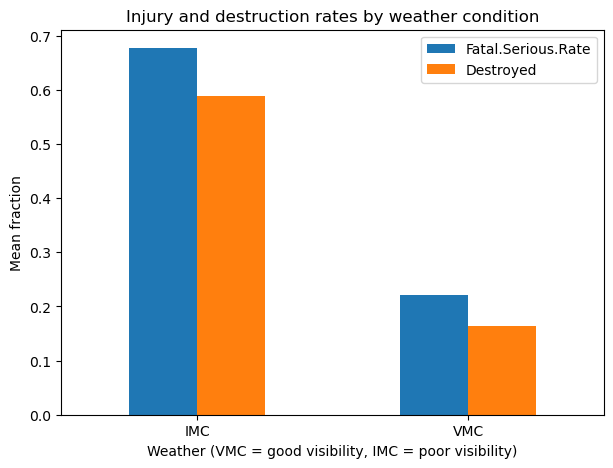

In [12]:
# injury rate and destruction rate by weather condition
weather = df.groupby('Weather.Condition')[['Fatal.Serious.Rate', 'Destroyed']].mean()
weather['count'] = df['Weather.Condition'].value_counts()
print(weather.round(3))

weather[['Fatal.Serious.Rate', 'Destroyed']].plot(kind='bar', figsize=(7, 5))
plt.title('Injury and destruction rates by weather condition')
plt.ylabel('Mean fraction')
plt.xlabel('Weather (VMC = good visibility, IMC = poor visibility)')
plt.xticks(rotation=0)
plt.show()

### Weather condition

- Weather makes a big difference. In accidents that happened in poor visibility (IMC), about 68% of people on board were killed or seriously injured and the plane was destroyed in 59% of cases. 
- In good visibility (VMC), those figures drop to 22% and 16%. 
- Accidents in bad weather are about three times as likely to be severe.

                   Fatal.Serious.Rate  Destroyed  count
Number.of.Engines                                      
1.0                             0.250      0.185  46313
2.0                             0.331      0.292   6872
3.0                             0.034      0.029    139
4.0                             0.157      0.140    107


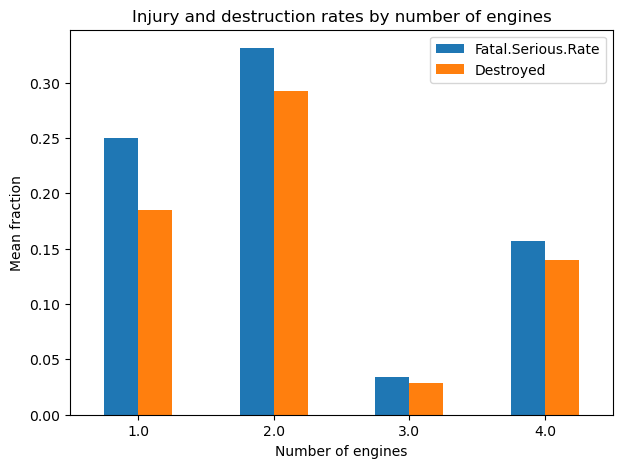

In [13]:
# injury rate and destruction rate by number of engines
engines = df.groupby('Number.of.Engines')[['Fatal.Serious.Rate', 'Destroyed']].mean()
engines['count'] = df['Number.of.Engines'].value_counts()
print(engines.round(3))

engines[['Fatal.Serious.Rate', 'Destroyed']].plot(kind='bar', figsize=(7, 5))
plt.title('Injury and destruction rates by number of engines')
plt.ylabel('Mean fraction')
plt.xlabel('Number of engines')
plt.xticks(rotation=0)
plt.show()

### Number of engines

More engines does not simply mean safer. Twin engine planes had more accidents than single engine planes (33% injured and 29% destroyed, against 25% and 19%). 
Three-engine planes do best so far.Four-engine planes are also a small group (107 accidents). 
Engine count on its own is not a good guide to safety, type and size of plane matter more.